In [224]:
import geopandas as gpd
import pandas as pd
import sys
import numpy as np

from pathlib import Path

locations = ['Blk_Air_23', 'Blk_Air_18', 'Blk_Air_51'] #51

REPO_ROOT = Path.cwd().parent.parent
# make the shared code in src/ importable even when the package is not pip-installed
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

In [225]:

src_dir = r"c:\Users\hermawan\OneDrive - Stichting Deltares\PhD\Egypt_ERF_data\Data\map"
excel_path = r"c:\Users\hermawan\OneDrive - Stichting Deltares\PhD\Egypt_ERF_data\Data\data_correlation.xlsx"

In [226]:
wage_df = pd.read_csv(REPO_ROOT / 'Results/wage_by_command_unit.csv')
productivity_df = pd.read_csv(REPO_ROOT / 'Results/group_productivity.csv', index_col=0)

In [227]:
map_df = wage_df.merge(productivity_df, on='area', how='left')

In [228]:
command_gdf = gpd.read_file(src_dir + '\Final2_Command_Area.shp')
conversion_df = pd.read_excel(excel_path, sheet_name='command_area')

mapping = conversion_df.merge(
    command_gdf[['Name', 'OBJECTID', 'geometry']],
    left_on = 'area_map_name',
    right_on = 'OBJECTID',
).set_index('area_name')["Name"]

# mapping = (
#     command_gdf.merge(
#         conversion_df[['area_map_name', 'area_name']],
#         left_on='OBJECTID',
#         right_on='area_map_name'
#     )
#     .set_index('Name')['area_map_name']
# )

# excel_salinity_df['area'] = excel_salinity_df['area'].map(mapping)

<>:1: SyntaxWarning: invalid escape sequence '\F'
<>:1: SyntaxWarning: invalid escape sequence '\F'
C:\Users\hermawan\AppData\Local\Temp\ipykernel_28256\176042714.py:1: SyntaxWarning: invalid escape sequence '\F'
  command_gdf = gpd.read_file(src_dir + '\Final2_Command_Area.shp')


In [229]:
map_df['area_name'] = map_df['area'].map(mapping)
map_df['geometry'] = map_df['area_name'].map(command_gdf.set_index('Name')['geometry'])
map_gdf = gpd.GeoDataFrame(map_df, geometry='geometry')
#map_gdf

In [230]:
command_gdf['area'] = command_gdf["Name"].map(mapping)
#command_gdf

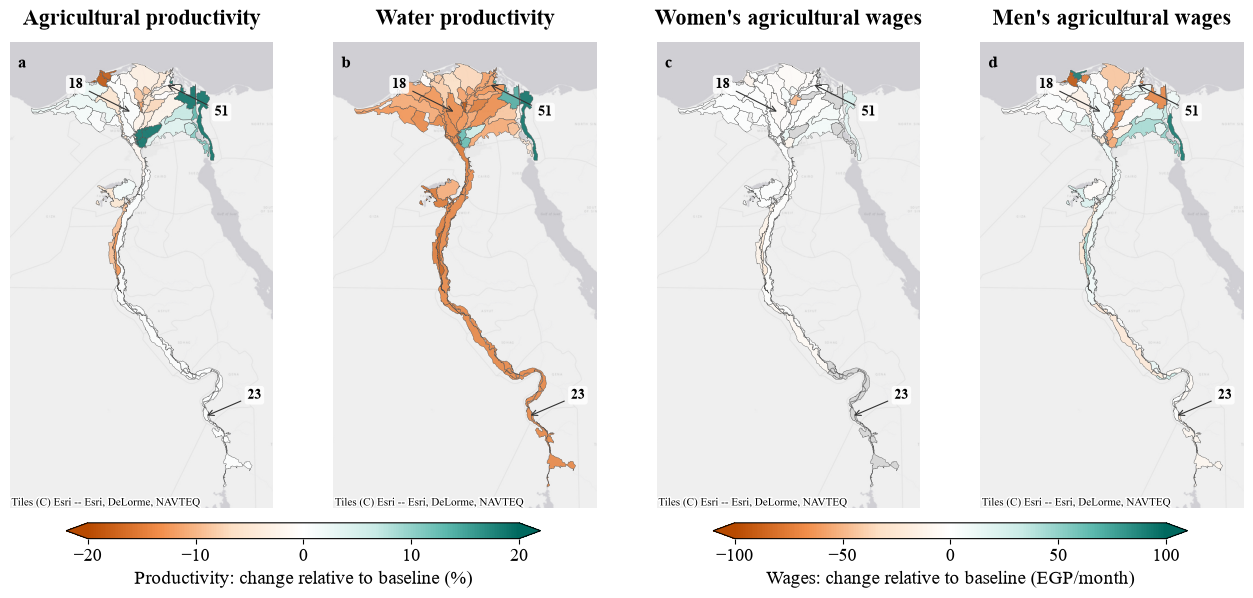

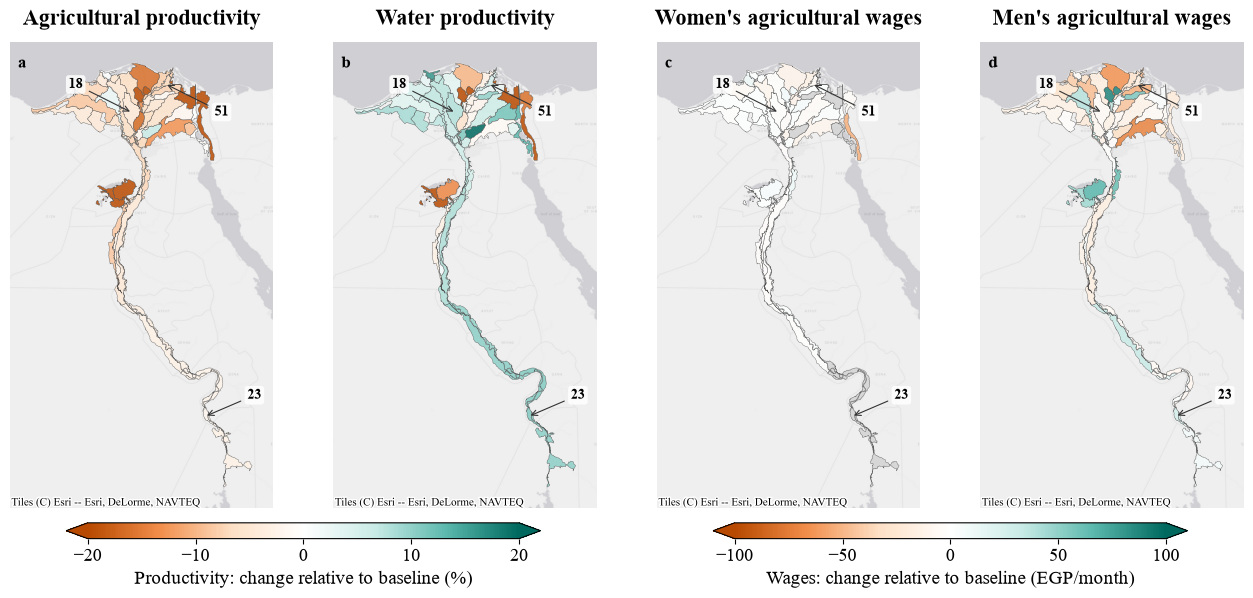

In [233]:
import contextily as cx
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable

label_column = 'area'
# Offsets follow the order of your existing locations list
label_offsets = [(35, 15), (-40, 20), (40, -20), (-40, -20), (35, 35), (-35, -35)]
FIGURE_DIR = REPO_ROOT / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
baseline, scenarios = '70', ['60', '80']
panels = [('agricultural_productivity', 'Agricultural productivity', 'productivity'), ('water_procuctivity', 'Water productivity', 'productivity'), ('female', "Women's agricultural wages", 'wages'), ('male', "Men's agricultural wages", 'wages')]
vlims = {'productivity': 20, 'wages': 100}
cbar_labels = {'productivity': f'Productivity: change relative to baseline (%)', 'wages': f'Wages: change relative to baseline (EGP/month)'}
cmap = LinearSegmentedColormap.from_list('orange_teal', ['#b84a00', '#f28e4b', '#fde0c5', '#ffffff', '#c9ebe6', '#5bb8ad', '#00695f'])
norms = {group: Normalize(vmin=-v, vmax=v) for group, v in vlims.items()}

for scenario in scenarios:
    plot_gdf = map_gdf.to_crs(epsg=3857).copy()
    for var, _, group in panels:
        base = plot_gdf[f'{var}_{baseline}']
        diff = plot_gdf[f'{var}_{scenario}'] - base
        plot_gdf[f'{var}_diff'] = diff / base.where(base != 0) * 100 if group == 'productivity' else diff

    selected = plot_gdf.loc[plot_gdf[label_column].isin(locations), [label_column, plot_gdf.geometry.name]]
    label_points = selected.dissolve(by=label_column).geometry.representative_point().to_dict() if not selected.empty else {}

    minx, miny, maxx, maxy = plot_gdf.total_bounds
    pad = 0.05 * max(maxx - minx, maxy - miny)
    fig, axes = plt.subplots(1, 4, figsize=(16, 6.5), sharex=True, sharey=True)

    for ax, (var, title, group), letter in zip(axes, panels, 'abcd'):
        ax.set_xlim(minx - pad, maxx + pad)
        ax.set_ylim(miny - pad, maxy + pad)
        plot_gdf.plot(column=f'{var}_diff', ax=ax, cmap=cmap, norm=norms[group], alpha=0.85, edgecolor='0.3', linewidth=0.3, missing_kwds={'color': 'lightgrey', 'edgecolor': '0.3', 'linewidth': 0.3})
        cx.add_basemap(ax, source=cx.providers.Esri.WorldGrayCanvas, crs=plot_gdf.crs, zoom=8)

        for i, name in enumerate(locations):
            point = label_points.get(name)
            if point is not None and not point.is_empty:
                offset = label_offsets[i % len(label_offsets)]
                ax.annotate(name.split('_')[-1], xy=(point.x, point.y), xytext=offset, textcoords='offset points', ha='center', va='center', fontsize=10, fontweight='bold', color='black', bbox={'boxstyle': 'round,pad=0.2', 'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.85}, arrowprops={'arrowstyle': '->', 'color': '0.2', 'lw': 0.8, 'shrinkA': 3, 'shrinkB': 1}, zorder=10)

        ax.set_title(title, fontweight='bold', y=1.02, pad=6)
        ax.text(0.03, 0.97, letter, transform=ax.transAxes, va='top', fontweight='bold', fontsize=12)
        ax.set_axis_off()

    for group, group_axes in [('productivity', axes[:2]), ('wages', axes[2:])]:
        v = vlims[group]
        cbar = fig.colorbar(ScalarMappable(norm=norms[group], cmap=cmap), ax=list(group_axes), orientation='horizontal', fraction=0.04, pad=0.03, aspect=30, shrink=0.8, extend='both')
        cbar.set_label(cbar_labels[group])
        cbar.set_ticks([-v, -v / 2, 0, v / 2, v])

    fig.savefig(FIGURE_DIR / f'map_plots_{baseline}_{scenario}.png', dpi=300, bbox_inches='tight')
    plt.show()

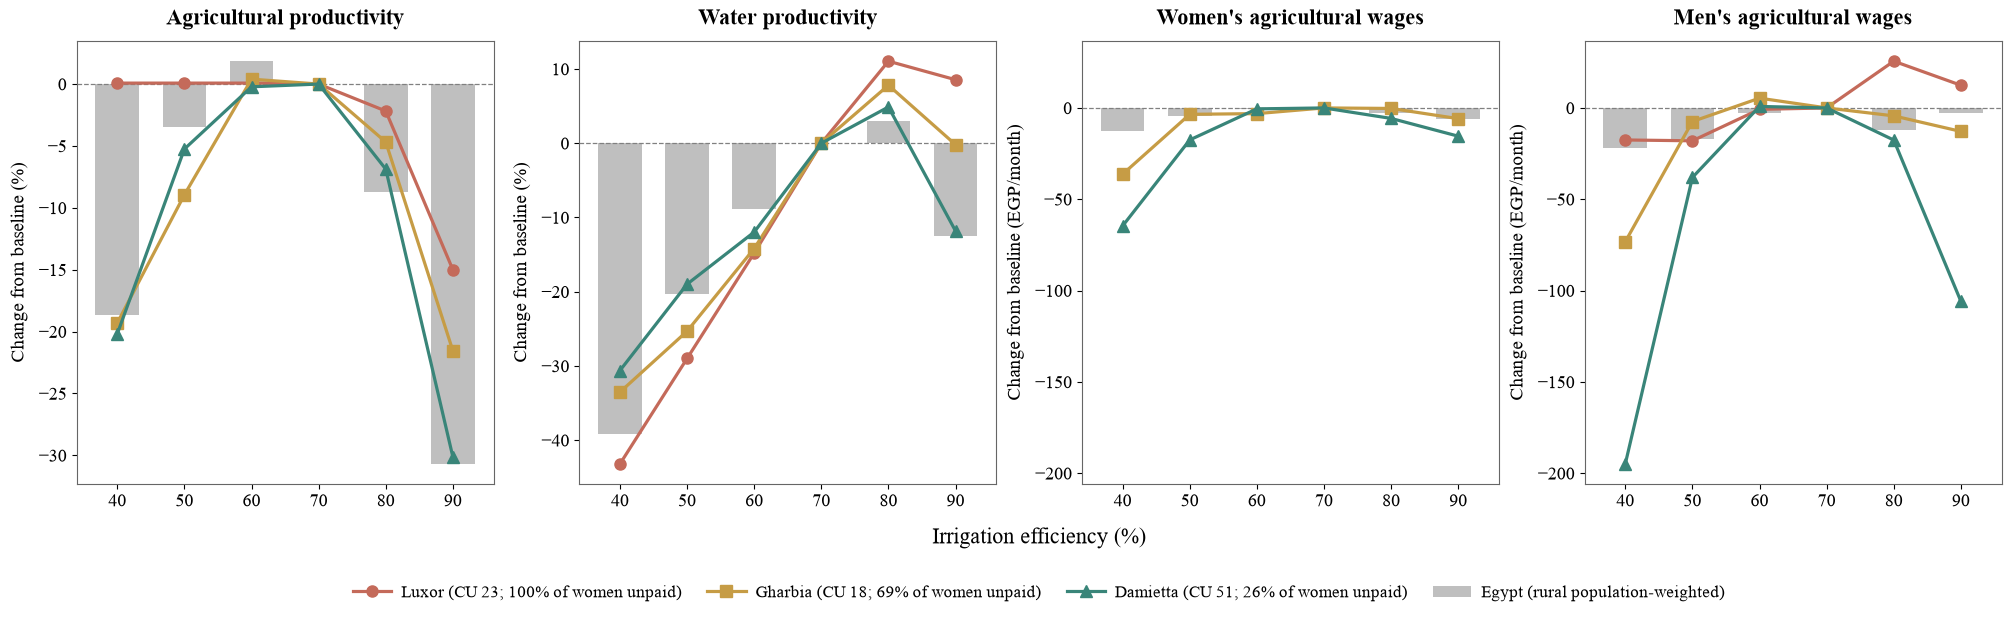

Saved: c:\Users\hermawan\OneDrive - Stichting Deltares\PhD\Egypt_ERF_data\figures\scenario_plot_multiple_locations.png


In [232]:


# Font settings
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman"], "font.size": 14,
    "axes.titlesize": 16, "axes.labelsize": 14, "xtick.labelsize": 13,
    "ytick.labelsize": 13, "legend.fontsize": 12, "pdf.fonttype": 42, "ps.fonttype": 42,
})

# Settings
scenarios = ["40", "50", "60", "70", "80", "90"]
baseline = "70"
legend_labels = {
    "Blk_Air_23": "Luxor (CU 23; 100% of women unpaid)",
    "Blk_Air_18": "Gharbia (CU 18; 69% of women unpaid)",
    "Blk_Air_63": "Ismailiya (CU 63; 39% of women unpaid)",
    'Blk_Air_51':"Damietta (CU 51; 26% of women unpaid)",
}
location_colors = ["#C46A5A", "#C69C45", "#398579", "#597DB5", "#9573AA", "#6F7645"]
location_markers = ["o", "s", "^", "D", "v", "P"]
location_column = "area"
weight_column = "rural_population"
min_baselines = {"agricultural_productivity": 0, "water_procuctivity": 0}

FIGURE_DIR = REPO_ROOT / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
panels = [
    ("agricultural_productivity", "Agricultural productivity", "productivity"),
    ("water_procuctivity", "Water productivity", "productivity"),
    ("female", "Women's agricultural wages", "wages"),
    ("male", "Men's agricultural wages", "wages"),
]

# Validate locations
if not locations:
    raise ValueError("Add at least one location to the locations list.")
rows = {}
for location in locations:
    selected = map_gdf.loc[map_gdf[location_column] == location]
    if len(selected) != 1:
        raise ValueError(f"Expected one row for '{location}', found {len(selected)}. Check map_gdf['{location_column}'].")
    rows[location] = selected.iloc[0]

# Figure: panels, shared x-label, shared legend
x = [int(s) for s in scenarios]
fig = plt.figure(figsize=(20, 6.2), constrained_layout=True)
grid = fig.add_gridspec(3, 4, height_ratios=[4, 0.35, 0.5])
axes = [fig.add_subplot(grid[0, i]) for i in range(4)]
xlabel_ax = fig.add_subplot(grid[1, :])
xlabel_ax.set_axis_off()
xlabel_ax.text(0.5, 0.5, "Irrigation efficiency (%)", ha="center", va="center", fontsize=16, transform=xlabel_ax.transAxes)
legend_ax = fig.add_subplot(grid[2, :])
legend_ax.set_axis_off()

# Background bars: rural population-weighted averages
weights = np.asarray(map_gdf[weight_column], dtype=float)
bar_width = min(np.diff(sorted(x))) * 0.65 if len(x) > 1 else 5

for ax, (var, title, group) in zip(axes, panels):
    baseline_values = np.asarray(map_gdf[f"{var}_{baseline}"], dtype=float)
    scenario_values = np.column_stack([np.asarray(map_gdf[f"{var}_{s}"], dtype=float) for s in scenarios])
    valid = np.isfinite(weights) & (weights > 0) & np.isfinite(baseline_values) & np.all(np.isfinite(scenario_values), axis=1)
    if not valid.any():
        raise ValueError(f"No areas with valid values and positive population for {var}.")
    baseline_mean = np.average(baseline_values[valid], weights=weights[valid])
    scenario_means = np.average(scenario_values[valid], axis=0, weights=weights[valid])
    overall_changes = scenario_means - baseline_mean
    if group == "productivity":
        if baseline_mean == 0 or abs(baseline_mean) < min_baselines[var]:
            overall_changes = np.zeros_like(scenario_means)
        else:
            overall_changes = overall_changes / baseline_mean * 100
    ax.bar(x, overall_changes, width=bar_width, color="#808080", alpha=0.5, edgecolor="none", zorder=1, label="Egypt (rural population-weighted)")

# Selected locations
for i, location in enumerate(locations):
    row = rows[location]
    color = location_colors[i % len(location_colors)]
    marker = location_markers[i % len(location_markers)]
    for ax, (var, title, group) in zip(axes, panels):
        values = np.array([row[f"{var}_{s}"] for s in scenarios], dtype=float)
        baseline_value = float(row[f"{var}_{baseline}"])
        change = values - baseline_value
        if group == "productivity":
            if baseline_value == 0 or abs(baseline_value) < min_baselines[var]:
                change = np.zeros_like(values)
            else:
                change = change / baseline_value * 100
        ax.plot(x, change, marker=marker, markersize=8, linewidth=2.3, color=color, markerfacecolor=color, markeredgecolor=color, markeredgewidth=1, label=legend_labels.get(location, location), zorder=3)

# Format panels
for ax, (_, title, group) in zip(axes, panels):
    ax.axhline(0, color="grey", linestyle="--", linewidth=0.9, zorder=2)
    ax.set_title(title, fontweight="bold", pad=12)
    ax.set_xticks(x)
    ax.set_ylabel("Change from baseline (%)" if group == "productivity" else "Change from baseline (EGP/month)", labelpad=8)
    ax.set_axisbelow(True)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_color("#666666")
        spine.set_linewidth(0.8)

# Same y-axis range for women's and men's wages
ymin = min(axes[2].get_ylim()[0], axes[3].get_ylim()[0])
ymax = max(axes[2].get_ylim()[1], axes[3].get_ylim()[1])
axes[3].sharey(axes[2])
axes[2].set_ylim(ymin, ymax)

# Shared legend on one line
handles, labels = axes[0].get_legend_handles_labels()
legend_ax.legend(handles, labels, loc="center", ncol=len(labels), frameon=False, handlelength=2.3, columnspacing=1.5, handletextpad=0.6)

# Save and show
output_path = FIGURE_DIR / "scenario_plot_multiple_locations.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {output_path}")